# RQ1 — Probability boxplots with Cliff's δ brackets

Builds a combined figure replacing the existing Figure 3 (`rq2_f1_scores.pdf`) and Table 4 (`tab:rq2_significant_effects`) for RQ1. For each (detector, model) cell the figure shows a boxplot of the detector's raw AI-probability per context, with significance brackets over context pairs whose Cliff's δ is medium or large. The δ values are the same ones that previously populated Table 4.

Output: `../../llm-in-prs-research-writing/figures/pdf/rq1_probability_boxplots.pdf`.

In [12]:
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CSV_PATH = '../datasets/temperature_1/run_3/detection_results.csv'
OUT_PDF = Path('../../../llm-in-prs-research-writing/figures/pdf/rq1_probability_boxplots.pdf')
OUT_PDF.parent.mkdir(parents=True, exist_ok=True)

TOOLS = ['roberta', 'roberta-qa', 'zerogpt']
TOOL_LABELS = {
    'roberta': 'ChatGPT Detector RoBERTa',
    'roberta-qa': 'ChatGPT-QA Detector RoBERTa',
    'zerogpt': 'ZeroGPT',
}
MODELS = ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']
MODEL_LABELS = {
    'Qwen/Qwen2.5-72B-Instruct': 'Qwen2.5-72B',
    'gpt-5-mini-2025-08-07': 'GPT-5-mini',
    'meta-llama/llama-3.1-70b-instruct': 'Llama-3.1-70B',
}
MODEL_COLORS = {
    'Qwen/Qwen2.5-72B-Instruct': '#1f77b4',
    'gpt-5-mini-2025-08-07': '#ff7f0e',
    'meta-llama/llama-3.1-70b-instruct': '#2ca02c',
}

VARIATION_ORDER = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
VARIATION_MAP = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File C.',
}
VARIATION_SHORT = ['Repo', 'Title', 'Diff', 'File', 'Issue', 'No-FC']  # x-axis tick labels

In [13]:
def cliffs_delta(a, b):
    a = np.asarray(a)
    b = np.asarray(b)
    if len(a) == 0 or len(b) == 0:
        return 0.0
    # Vectorised O(m*n) via broadcasting; fine for our sizes (<= ~308x308)
    diff = a[:, None] - b[None, :]
    return (np.sign(diff).sum()) / (len(a) * len(b))

def interpret(d):
    d = abs(d)
    if d < 0.147:
        return 'N'
    if d < 0.33:
        return 'S'
    if d < 0.474:
        return 'M'
    return 'L'

df = pd.read_csv(CSV_PATH)
ai = df[df['entry_type'] == 'ai'].copy()
print('AI rows loaded:', len(ai))
print('Variations:', sorted(ai['variation'].unique()))
print('Models:', sorted(ai['model'].unique()))

AI rows loaded: 5528
Variations: ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
Models: ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']


In [14]:
# Precompute all pairwise Cliff's deltas per (tool, model, va, vb)
delta_rows = []
for tool in TOOLS:
    prob_col = f'{tool}_ai_probability'
    for model in MODELS:
        for va, vb in itertools.combinations(VARIATION_ORDER, 2):
            a = ai[(ai['model'] == model) & (ai['variation'] == va)][prob_col].dropna().values
            b = ai[(ai['model'] == model) & (ai['variation'] == vb)][prob_col].dropna().values
            if len(a) == 0 or len(b) == 0:
                continue
            d = cliffs_delta(a, b)
            delta_rows.append({
                'tool': tool,
                'model': model,
                'va': va,
                'vb': vb,
                'delta': d,
                'magnitude': interpret(d),
            })
delta_df = pd.DataFrame(delta_rows)
print('Total pairwise δs:', len(delta_df))
print('Magnitude counts:', delta_df['magnitude'].value_counts().to_dict())
delta_df.head()

Total pairwise δs: 135
Magnitude counts: {'S': 47, 'N': 43, 'L': 26, 'M': 19}


,tool,model,va,vb,delta,magnitude
0,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-2,-0.583237,L
1,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-3,0.045500,N
2,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-4,-0.198743,S
3,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-5,-0.059687,N
4,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-6,0.009772,N


In [15]:
def draw_bracket(ax, x1, x2, y, label, color='black'):
    """Draw a horizontal bracket from x1 to x2 at height y with `label` on top."""
    tick = 0.022
    ax.plot([x1, x1, x2, x2], [y - tick, y, y, y - tick], lw=0.7, c=color, clip_on=False)
    ax.text((x1 + x2) / 2, y + 0.012, label, ha='center', va='bottom', fontsize=10, color=color, clip_on=False)

MAX_BRACKETS_PER_PANEL = 5  # cap clutter; ranked by |delta|

def plot_panel(ax, ai_subset, tool, model, deltas_for_cell, show_x=True, show_y=True):
    prob_col = f'{tool}_ai_probability'
    data_per_var = []
    counts = []
    for v in VARIATION_ORDER:
        vals = ai_subset[(ai_subset['model'] == model) & (ai_subset['variation'] == v)][prob_col].dropna().values
        data_per_var.append(vals)
        counts.append(len(vals))

    color = MODEL_COLORS[model]
    positions = np.arange(len(VARIATION_ORDER))
    ax.boxplot(
        data_per_var,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=True,
        flierprops=dict(marker='.', markersize=2, alpha=0.35),
        medianprops=dict(color='black', lw=1.0),
        boxprops=dict(facecolor=color, alpha=0.65, edgecolor='black', lw=0.7),
        whiskerprops=dict(color='black', lw=0.7),
        capprops=dict(color='black', lw=0.7),
    )

    ax.set_ylim(-0.02, 2.05)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticks(positions)
    ax.set_xticklabels(VARIATION_SHORT, fontsize=12, rotation=30, ha='right')
    if not show_x:
        ax.set_xticklabels([])
    if show_y:
        ax.set_ylabel('AI probability', fontsize=12)
    ax.tick_params(axis='both', labelsize=12)
    ax.grid(axis='y', linestyle=':', alpha=0.4)
    ax.axhline(0.5, color='gray', linestyle='--', lw=0.6, alpha=0.55)

    # Brackets for medium+large effects only, capped at MAX_BRACKETS_PER_PANEL
    sig = deltas_for_cell[deltas_for_cell['magnitude'].isin(['M', 'L'])].copy()
    sig['abs_delta'] = sig['delta'].abs()
    sig = sig.sort_values('abs_delta', ascending=False).head(MAX_BRACKETS_PER_PANEL)
    n_shown = len(sig)
    n_total = len(deltas_for_cell[deltas_for_cell['magnitude'].isin(['M', 'L'])])

    base_y = 1.08
    step = 0.17
    for i, (_, row) in enumerate(sig.iterrows()):
        x1 = VARIATION_ORDER.index(row['va'])
        x2 = VARIATION_ORDER.index(row['vb'])
        y = base_y + i * step
        label = f"{row['magnitude']}{row['delta']:+.2f}"
        draw_bracket(ax, x1, x2, y, label)

    # If we capped, note the omitted count
    if n_total > n_shown:
        ax.text(
            len(VARIATION_ORDER) - 0.5, 2.00, f"+{n_total - n_shown} more (M/L)",
            ha='right', va='top', fontsize=7, color='dimgray', style='italic',
        )

    # Per-context n at the bottom — use pixel offset so it sits *below* rotated x-tick labels
    # (offset depends on whether tick labels are shown for this row)
    yoffset_pts = -38 if show_x else -8
    for x, n in zip(positions, counts):
        ax.annotate(
            f'n={n}',
            xy=(x, 0), xycoords=('data', 'axes fraction'),
            xytext=(0, yoffset_pts), textcoords='offset points',
            ha='center', va='top', fontsize=9, color='dimgray',
            annotation_clip=False,
        )

Saved: ../../../llm-in-prs-research-writing/figures/pdf/rq1_probability_boxplots.pdf


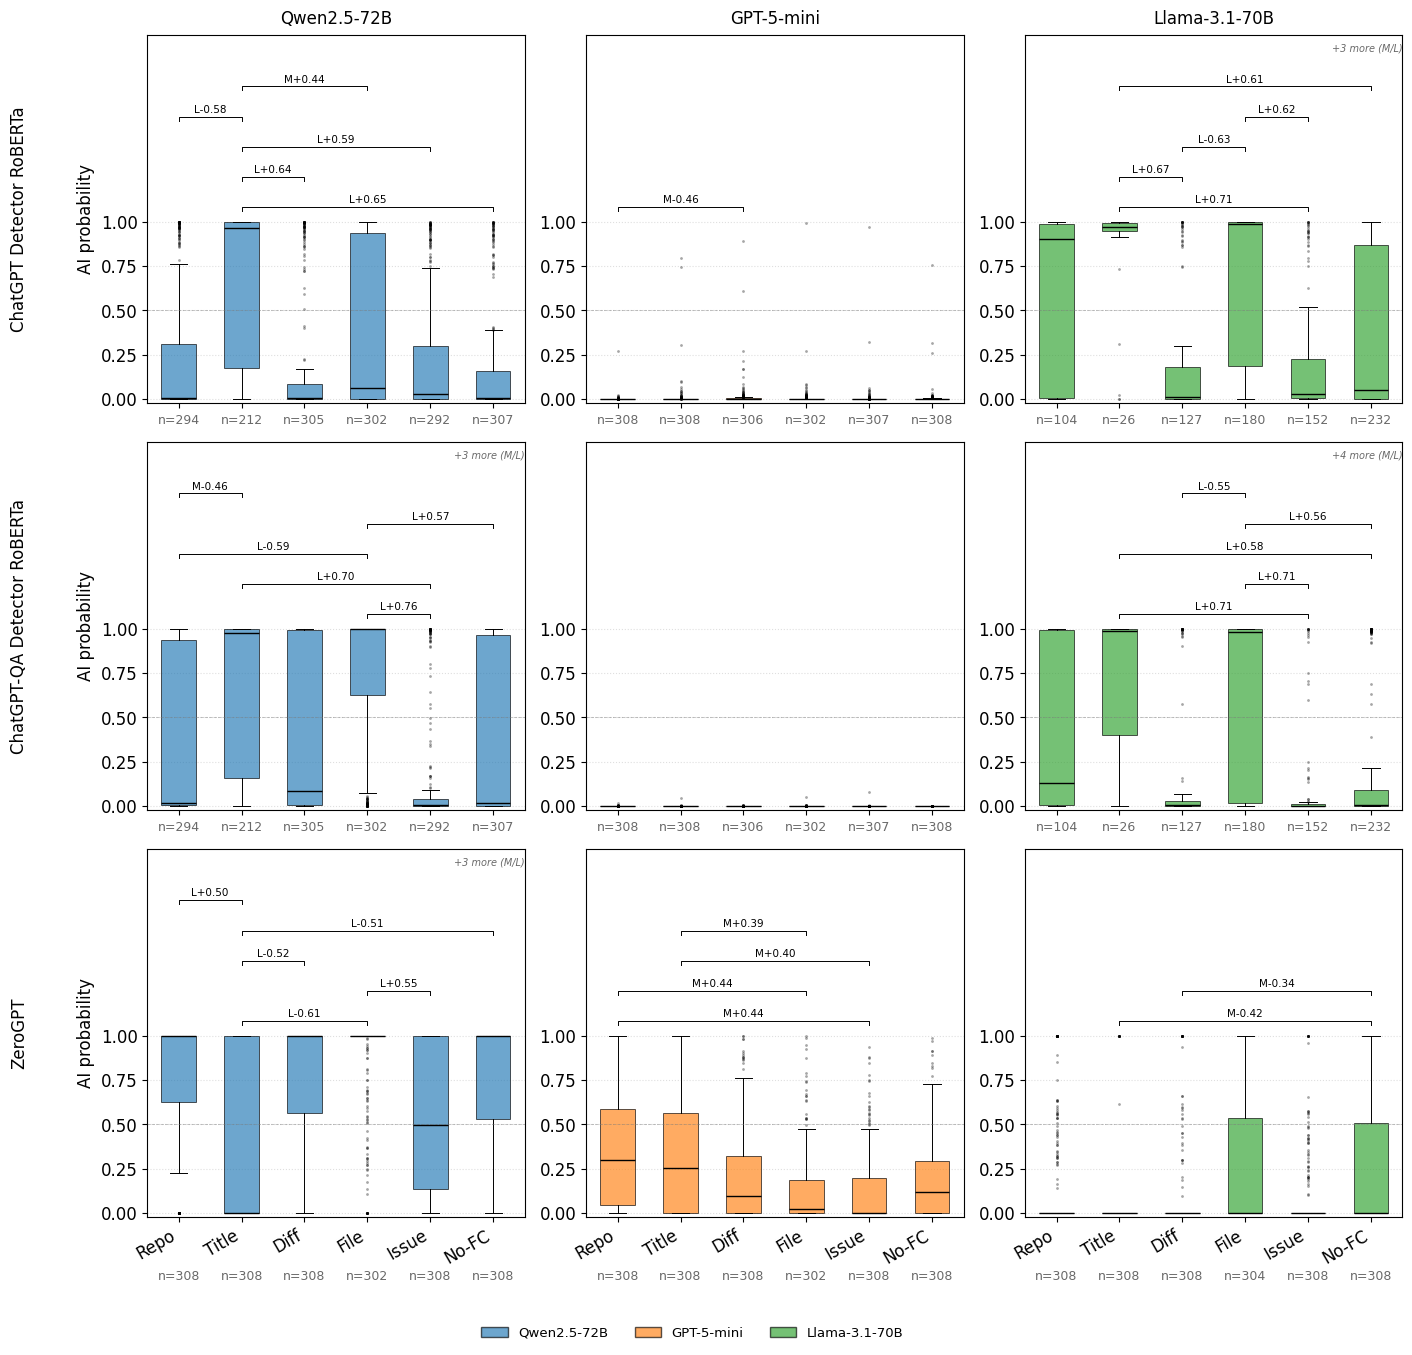

In [16]:
fig, axes = plt.subplots(
    nrows=len(TOOLS), ncols=len(MODELS),
    figsize=(14.5, 13.5), sharey=False,
)

for r, tool in enumerate(TOOLS):
    for c, model in enumerate(MODELS):
        ax = axes[r, c]
        deltas = delta_df[(delta_df['tool'] == tool) & (delta_df['model'] == model)]
        plot_panel(
            ax, ai, tool, model, deltas,
            show_x=(r == len(TOOLS) - 1),
            show_y=(c == 0),
        )
        if r == 0:
            ax.set_title(MODEL_LABELS[model], fontsize=12, pad=8)
        if c == 0:
            ax.text(
                -0.34, 0.5, TOOL_LABELS[tool],
                transform=ax.transAxes, rotation=90, va='center', ha='center',
                fontsize=12,
            )

legend_handles = [
    Patch(facecolor=MODEL_COLORS[m], alpha=0.65, edgecolor='black', label=MODEL_LABELS[m])
    for m in MODELS
]
fig.legend(
    handles=legend_handles,
    loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.005),
    frameon=False, fontsize=9.5,
)

fig.tight_layout(rect=[0.03, 0.035, 1, 1.0])
fig.savefig(OUT_PDF, bbox_inches='tight')
fig.savefig(str(OUT_PDF).replace('.pdf', '.png'), dpi=170, bbox_inches='tight')
print('Saved:', OUT_PDF)
plt.show()

In [17]:
# Diagnostics: how many brackets per panel?
diag = (
    delta_df[delta_df['magnitude'].isin(['M', 'L'])]
    .groupby(['tool', 'model'])
    .size()
    .reset_index(name='n_brackets')
    .sort_values('n_brackets', ascending=False)
)
diag

,tool,model,n_brackets
4,roberta-qa,meta-llama/llama-3.1-70b-instruct,9
2,roberta,meta-llama/llama-3.1-70b-instruct,8
3,roberta-qa,Qwen/Qwen2.5-72B-Instruct,8
5,zerogpt,Qwen/Qwen2.5-72B-Instruct,8
0,roberta,Qwen/Qwen2.5-72B-Instruct,5
6,zerogpt,gpt-5-mini-2025-08-07,4
7,zerogpt,meta-llama/llama-3.1-70b-instruct,2
1,roberta,gpt-5-mini-2025-08-07,1
